# Centred map

In [21]:
import numpy as np 
import torch
import matplotlib.pyplot as plt
from cosmology import Cosmology
from nfw import NFWHalo
from lensing import shear_profile

cosmology = Cosmology()
M200c = 1e15
c200c = 4.0
z_lens = 0.3
z_source = 1.0

centre = (0.0, 0.0)

theta = [np.log10(M200c), c200c, centre[0], centre[1], z_lens, z_source]

halo = NFWHalo(
    theta=theta,
    z_l=0.3,              # Lens redshift
    cosmology=cosmology,
)

r_s, rho_s = halo.nfw_parameters()
# Choose 30 projected physical radii from 0.1 to 3 Mpc.
R = np.geomspace(0.1, 3.0, 30)

Sigma, Sigma_mean = halo.surface_densities(R)
DeltaSigma = Sigma_mean - Sigma

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)
g_t = shear_profile(
    theta=theta,
    R=R,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

## 1D radial bins map
### Noisy bin-radial profile

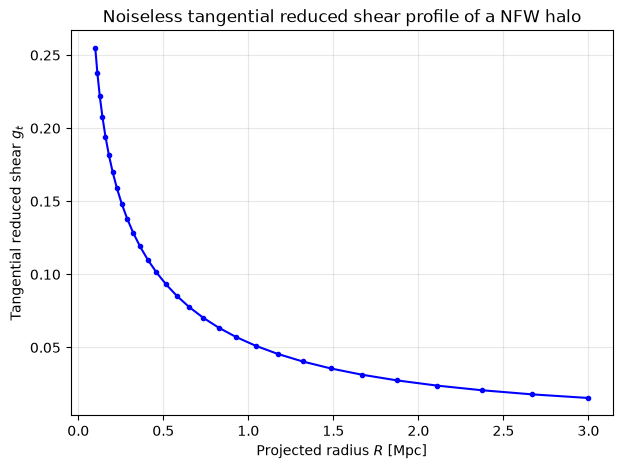

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(R, g_t, "o-", markersize=3, color="blue")
ax.set(
    ylabel='Tangential reduced shear $g_t$', xlabel='Projected radius $R$ [Mpc]',
    title='Noiseless tangential reduced shear profile of a NFW halo'
)
ax.grid(alpha=0.3)
plt.show()

### Noisy radial-bin profile

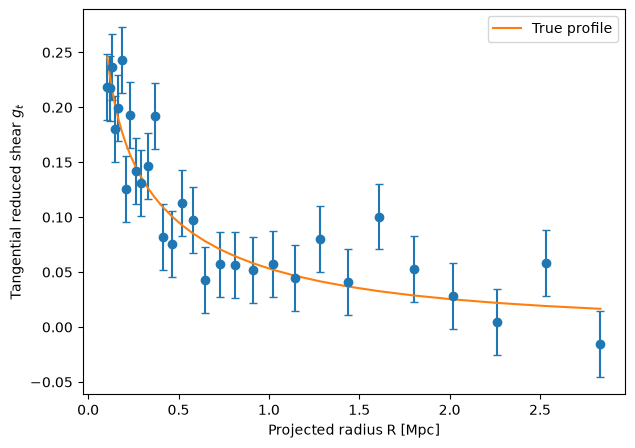

In [23]:
from lensing import simulate

# 30 radial bins
n_bins = 30
bin_edges = np.geomspace(0.1, 3.0, n_bins + 1)
R_bins = np.sqrt(bin_edges[:-1] * bin_edges[1:])

# 2. Specify galaxy counts and uncertainty per galaxy
N_bin = np.full(n_bins, 100)  # Replace with your count for each bin
sigma_galaxy = 0.3           # Standard deviation of the tangential component
sigma_bin = sigma_galaxy / np.sqrt(N_bin)

# Simulate noisy bin averages directly
g_obs = simulate(
    theta=theta,
    R=R_bins,
    sigma=sigma_bin,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

# Expected profile at the same radii
g_true = shear_profile(
    theta=theta,
    R=R_bins,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    R_bins, g_obs.numpy(), yerr=sigma_bin,
    fmt="o", capsize=3,
)
ax.plot(R_bins, g_true.numpy(), label="True profile")
ax.legend()
ax.set(
    xlabel="Projected radius R [Mpc]",
    ylabel="Tangential reduced shear $g_t$",
)
plt.show()

## 2D map

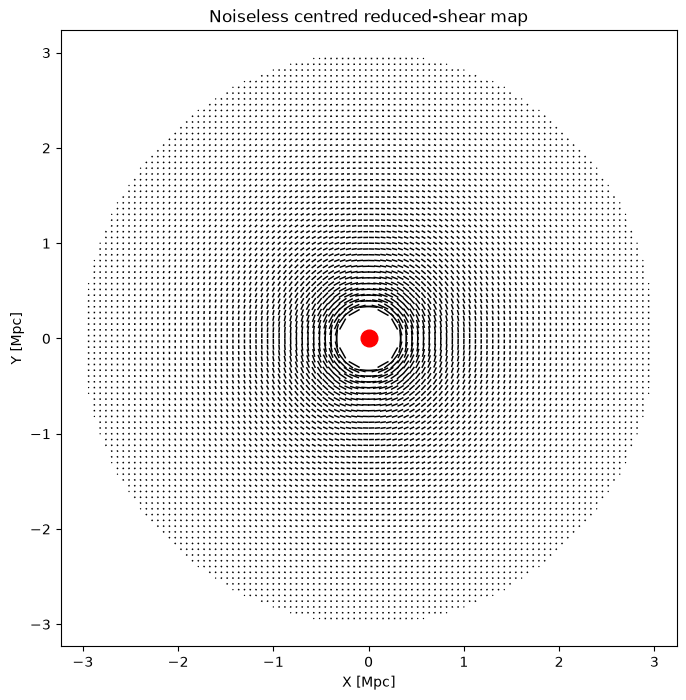

In [24]:
#Choose positions and calculate their geometry
axis = np.linspace(-3.0, 3.0, 100)
x, y = np.meshgrid(axis, axis)

xc, yc = centre
dx, dy = x - xc, y - yc

R = np.hypot(dx, dy)
phi = np.arctan2(dy, dx)
mask = (R >= 0.3) & (R <= 3.0)

gt_map = np.zeros_like(R)
gt_map[mask] = shear_profile(
    theta=theta,
    R=R[mask],
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

g1 = -gt_map * np.cos(2 * phi)
g2 = -gt_map * np.sin(2 * phi)

amplitude = np.hypot(g1, g2)
orientation = 0.5 * np.arctan2(g2, g1)  # orientation of the shear in radians

u = amplitude * np.cos(orientation)
v = amplitude * np.sin(orientation)

fig, ax = plt.subplots(figsize=(8, 8))
ax.quiver(
    x[mask], y[mask], u[mask], v[mask],
    angles='xy', scale_units='xy', scale=1,
    pivot="middle",
    headwidth=0, headlength=0, headaxislength=0
    )
ax.plot(xc, yc, 'ro', markersize=12, label='Halo Center')
ax.set(
    xlabel='X [Mpc]', ylabel='Y [Mpc]',
    title="Noiseless centred reduced-shear map",
    aspect='equal'
)
plt.show()

In [25]:
#Check that conversion works

gt_recovered = -g1 * np.cos(2 * phi) - g2 * np.sin(2 * phi)
gx_recovered = -g1 * np.sin(2 * phi) + g2 * np.cos(2 * phi)

np.testing.assert_allclose(gt_recovered[mask], gt_map[mask], rtol=1e-12, atol=1e-14)
np.testing.assert_allclose(gx_recovered[mask], 0.0, atol=1e-14)
print("Conversion checks passed.")
print(
    "Maximum tangential reconstruction error:",
    np.max(np.abs(gt_recovered[mask] - gt_map[mask]))
)
print(
    "Maximum absolute cross component:",
    np.max(np.abs(gx_recovered[mask]))
)

Conversion checks passed.
Maximum tangential reconstruction error: 2.7755575615628914e-17
Maximum absolute cross component: 6.938893903907228e-18


# Displaced-centre geometry

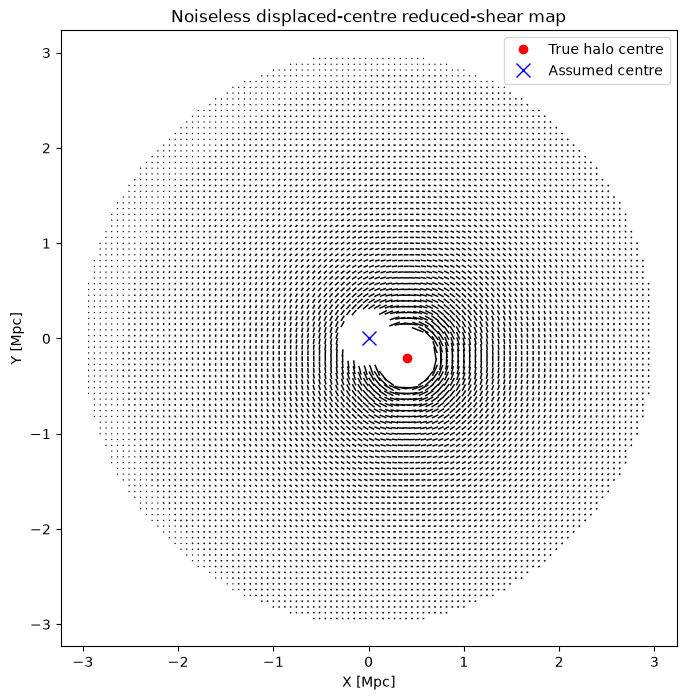

In [26]:
true_centre = (0.4, -0.2)
assumed_centre = (0.0, 0.0)

axis = np.linspace(-3.0, 3.0, 100)
x, y = np.meshgrid(axis, axis)

#Relative to true halo centre
dx_true = x - true_centre[0]
dy_true = y - true_centre[1]

R_true = np.hypot(dx_true, dy_true)
phi_true = np.arctan2(dy_true, dx_true)

#Relative to assumed halo centre
dx_assumed = x - assumed_centre[0]
dy_assumed = y - assumed_centre[1]

R_assumed = np.hypot(dx_assumed, dy_assumed)
phi_assumed = np.arctan2(dy_assumed, dx_assumed)

mask = (
    (R_assumed >= 0.3)
    & (R_assumed <= 3.0)
    & (R_true >= 0.3)
)

gt_map = np.zeros_like(R_true)
gt_map[mask] = shear_profile(
    theta=theta,
    R=R_true[mask],
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

# Generate the physical field around the true halo centre.
g1 = -gt_map * np.cos(2 * phi_true)
g2 = -gt_map * np.sin(2 * phi_true)

gt_assumed = -g1 * np.cos(2 * phi_assumed) - g2 * np.sin(2 * phi_assumed)
gx_assumed = -g1 * np.sin(2 * phi_assumed) + g2 * np.cos(2 * phi_assumed)

# Recompute plotting sticks from the displaced field.
amplitude = np.hypot(g1, g2)
orientation = 0.5 * np.arctan2(g2, g1)
u = amplitude * np.cos(orientation)
v = amplitude * np.sin(orientation)

fig, ax = plt.subplots(figsize=(8, 8))
ax.quiver(
    x[mask], y[mask], u[mask], v[mask],
    angles='xy', scale_units='xy', scale=1,
    pivot="middle",
    headwidth=0, headlength=0, headaxislength=0
    )
ax.plot(*true_centre, "ro", label="True halo centre")
ax.plot(*assumed_centre, "bx", markersize=10, label="Assumed centre")
ax.set(
    xlabel='X [Mpc]', ylabel='Y [Mpc]',
    title="Noiseless centred reduced-shear map",
    aspect='equal'
)
ax.set_title("Noiseless displaced-centre reduced-shear map")
ax.legend()
plt.show()

In [27]:
gt_true = (
    -g1 * np.cos(2 * phi_true)
    - g2 * np.sin(2 * phi_true)
)
gx_true = (
    -g1 * np.sin(2 * phi_true)
    + g2 * np.cos(2 * phi_true)
)

np.testing.assert_allclose(
    gt_true[mask], gt_map[mask], rtol=1e-12, atol=1e-14
)
np.testing.assert_allclose(gx_true[mask], 0.0, atol=1e-14)

print("True-centre checks passed.")
print("Maximum |gx| around assumed centre:",
      np.max(np.abs(gx_assumed[mask])))

True-centre checks passed.
Maximum |gx| around assumed centre: 0.1286688702913126


## 2D extension

2D observation shape: (1, 2, 100, 100)


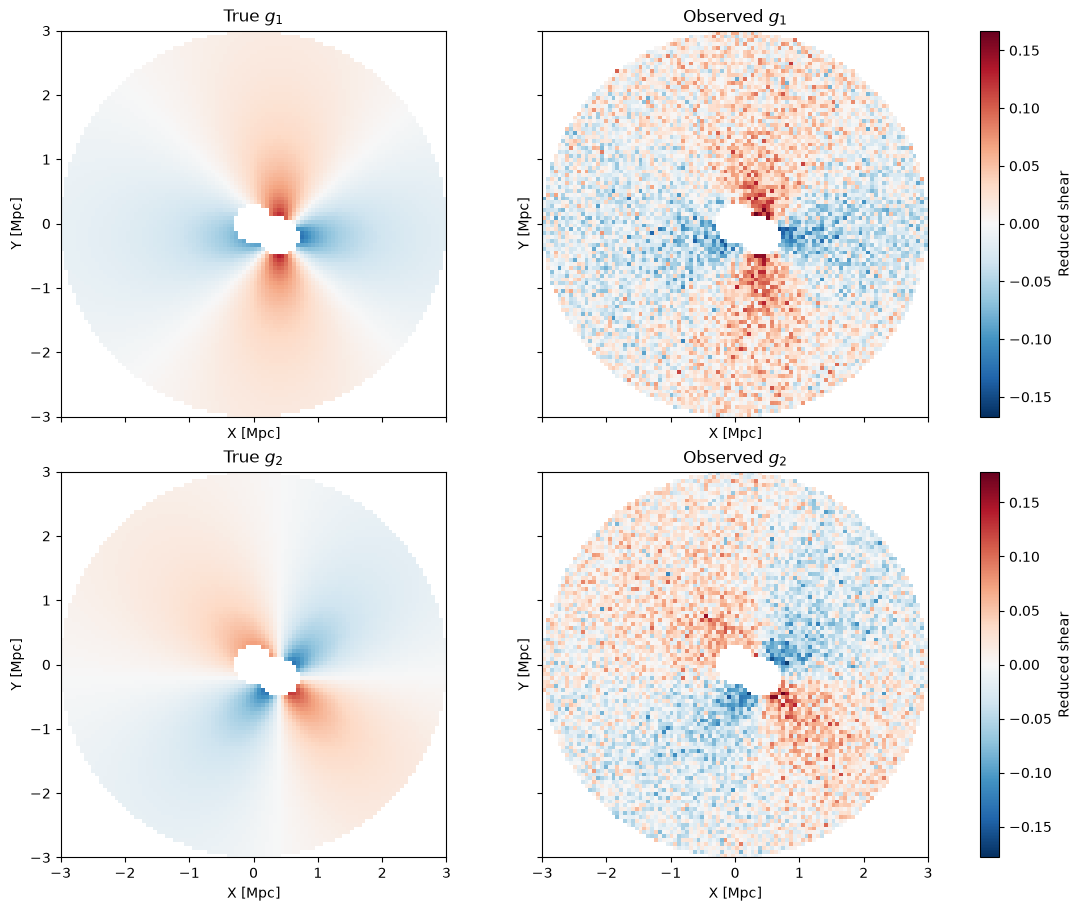

In [28]:
from lensing import simulate_map

# Directly simulate pixel-averaged shear
map_half_width = 3.0  # Mpc
n_side = 100
pixel_edges = np.linspace(-map_half_width, map_half_width, n_side + 1)
pixel_centres = 0.5 * (pixel_edges[:-1] + pixel_edges[1:])
x, y = np.meshgrid(pixel_centres, pixel_centres)
pixel_size = pixel_edges[1] - pixel_edges[0]
pixel_area = pixel_size**2

true_centre = (0.4, -0.2)
assumed_centre = (0.0, 0.0)
R_true = np.hypot(x - true_centre[0], y - true_centre[1])
R_assumed = np.hypot(x - assumed_centre[0], y - assumed_centre[1])

# Select the observed region; exclude the central model region.
mask = (R_assumed >= 0.3) & (R_assumed <= 3.0) & (R_true >= 0.3)

# Illustrative galaxy count per pixel; replace with observational counts.
N_per_pixel = 100
sigma_galaxy = 0.3
count_map = np.where(mask, N_per_pixel, 0)

torch.manual_seed(42)  # Reproducible example
# Keep 2D names separate from the earlier 1D g_obs and g_true.
g_obs_map, g_true_map, sigma_pixel, valid = simulate_map(
    theta=theta,
    x=x,
    y=y,
    centre=true_centre,
    mask=mask,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
    N_per_pixel=count_map,
    sigma_galaxy=sigma_galaxy,
)

# Convert the returned tensors for plotting
g1_true, g2_true = g_true_map.detach().cpu().numpy()
g1_obs, g2_obs = g_obs_map.detach().cpu().numpy()
mask = valid.cpu().numpy()
sigma_map = np.where(mask, sigma_pixel.cpu().numpy(), np.nan)

# [batch, channels, height, width]; keep valid alongside this input.
g_true_2d = g_true_map.unsqueeze(0)
g_obs_2d = g_obs_map.unsqueeze(0)
print("2D observation shape:", tuple(g_obs_2d.shape))

#Plotting
fig, axes = plt.subplots(
    2, 2, figsize=(11, 9),
    sharex=True, sharey=True,
    constrained_layout=True,
)
maps = [
    [g1_true, g1_obs],
    [g2_true, g2_obs],
]
titles = [
    ["True $g_1$", "Observed $g_1$"],
    ["True $g_2$", "Observed $g_2$"],
]
for row in range(2):
    # Same colour scale for the true/observed pair
    limit = max(
        np.max(np.abs(maps[row][0][mask])),
        np.max(np.abs(maps[row][1][mask])),
    )
    limit = max(float(limit), 1e-12)

    for col in range(2):
        values = np.ma.array(maps[row][col], mask=~mask)

        im = axes[row, col].pcolormesh(
            pixel_edges, pixel_edges, values,
            cmap="RdBu_r",
            vmin=-limit, vmax=limit,
            shading="flat",
        )
        axes[row, col].set(
            title=titles[row][col],
            xlabel="X [Mpc]",
            ylabel="Y [Mpc]",
            aspect="equal",
        )

    fig.colorbar(im, ax=axes[row, :], label="Reduced shear")

plt.show()


# Radial and sector summaries

## Radial compression

Ring 0: 24 valid pixels
Ring 1: 27 valid pixels
Ring 2: 47 valid pixels
Ring 3: 49 valid pixels
Ring 4: 84 valid pixels
Ring 5: 113 valid pixels
Ring 6: 188 valid pixels
Ring 7: 232 valid pixels
Ring 8: 328 valid pixels
Ring 9: 456 valid pixels
Ring 10: 596 valid pixels
Ring 11: 836 valid pixels
Ring 12: 1136 valid pixels
Ring 13: 1528 valid pixels
Ring 14: 2068 valid pixels


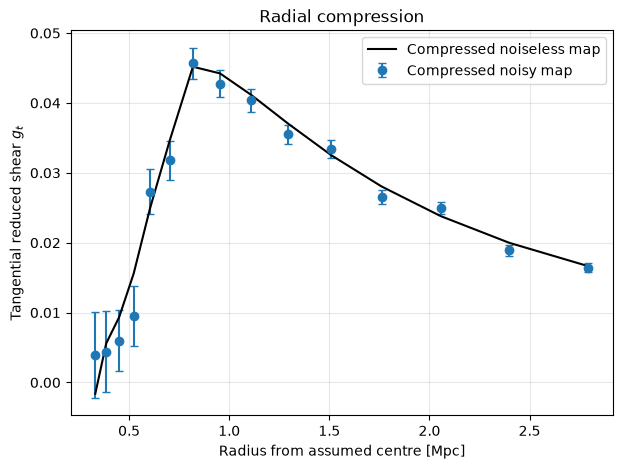

In [29]:
#Pixel 
map_half_width = 3.0  # Mpc
n_side = 100
pixel_edges = np.linspace(-map_half_width, map_half_width, n_side + 1)
pixel_centres = 0.5 * (pixel_edges[:-1] + pixel_edges[1:])
x, y = np.meshgrid(pixel_centres, pixel_centres)
pixel_size = pixel_edges[1] - pixel_edges[0]
pixel_area = pixel_size**2

true_centre = (0.4, -0.2)
assumed_centre = (0.0, 0.0)
R_true = np.hypot(x - true_centre[0], y - true_centre[1])
phi_assumed = np.arctan2(y - assumed_centre[1], x - assumed_centre[0])

#Calculating each pixel's geometry relative to the assumed centre
R_analysis = np.hypot(x - assumed_centre[0], y - assumed_centre[1])

#Converting noisy components to tangential shear
g1_true, g2_true = g_true_map.detach().cpu().numpy()
g1_obs, g2_obs = g_obs_map.detach().cpu().numpy()
gt_obs = -g1_obs * np.cos(2 * phi_assumed) - g2_obs * np.sin(2 * phi_assumed)

#Radial binning
n_bins = 15
bin_edges = np.geomspace(0.3, 3.0, n_bins + 1)
sigma = sigma_pixel.detach().cpu().numpy()
valid_pixels = (
    valid.cpu().numpy()
    & np.isfinite(sigma)
    & (sigma > 0)
)

gt_true = (
    -g1_true * np.cos(2 * phi_assumed)
    -g2_true * np.sin(2 * phi_assumed)
)

R_radial = np.full(n_bins, np.nan)
gt_radial = np.full(n_bins, np.nan)
gt_true_radial = np.full(n_bins, np.nan)
sigma_radial = np.full(n_bins, np.nan)
pixel_counts = np.zeros(n_bins, dtype=int)

for b in range(n_bins):
    # Select pixels between the inner and outer edges
    in_ring = (
        valid_pixels
        & (R_analysis >= bin_edges[b])
        & (R_analysis < bin_edges[b + 1])
    )

    # Include the outermost boundary in the last ring
    if b == n_bins - 1:
        in_ring = (
            valid_pixels
            & (R_analysis >= bin_edges[b])
            & (R_analysis <= bin_edges[b + 1])
        )

    print(f"Ring {b}: {in_ring.sum()} valid pixels")

    pixel_counts[b] = in_ring.sum()
    if pixel_counts[b] == 0:
        continue

    #Weighted mean in each ring
    weights = 1.0 / sigma[in_ring]**2
    weight_sum = weights.sum()

    R_radial[b] = np.sum(weights * R_analysis[in_ring]) / weight_sum
    gt_radial[b] = np.sum(weights * gt_obs[in_ring]) / weight_sum
    gt_true_radial[b] = np.sum(weights * gt_true[in_ring]) / weight_sum
    sigma_radial[b] = 1.0 / np.sqrt(weight_sum)

populated = pixel_counts > 0

#Plotting
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    R_radial[populated],
    gt_radial[populated],
    yerr=sigma_radial[populated],
    fmt="o", capsize=3,
    label="Compressed noisy map",
)
ax.plot(
    R_radial[populated],
    gt_true_radial[populated],
    "k-",
    label="Compressed noiseless map",
)
ax.set(
    xlabel="Radius from assumed centre [Mpc]",
    ylabel="Tangential reduced shear $g_t$",
    title="Radial compression",
)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Sector compression

Sector 0: 6 valid pixels
Sector 1: 8 valid pixels
Sector 2: 8 valid pixels
Sector 3: 2 valid pixels
Sector 0: 7 valid pixels
Sector 1: 9 valid pixels
Sector 2: 9 valid pixels
Sector 3: 2 valid pixels
Sector 0: 13 valid pixels
Sector 1: 15 valid pixels
Sector 2: 15 valid pixels
Sector 3: 4 valid pixels
Sector 0: 14 valid pixels
Sector 1: 15 valid pixels
Sector 2: 15 valid pixels
Sector 3: 5 valid pixels
Sector 0: 24 valid pixels
Sector 1: 25 valid pixels
Sector 2: 25 valid pixels
Sector 3: 10 valid pixels
Sector 0: 31 valid pixels
Sector 1: 31 valid pixels
Sector 2: 31 valid pixels
Sector 3: 20 valid pixels
Sector 0: 47 valid pixels
Sector 1: 47 valid pixels
Sector 2: 47 valid pixels
Sector 3: 47 valid pixels
Sector 0: 58 valid pixels
Sector 1: 58 valid pixels
Sector 2: 58 valid pixels
Sector 3: 58 valid pixels
Sector 0: 82 valid pixels
Sector 1: 82 valid pixels
Sector 2: 82 valid pixels
Sector 3: 82 valid pixels
Sector 0: 114 valid pixels
Sector 1: 114 valid pixels
Sector 2: 114 valid 

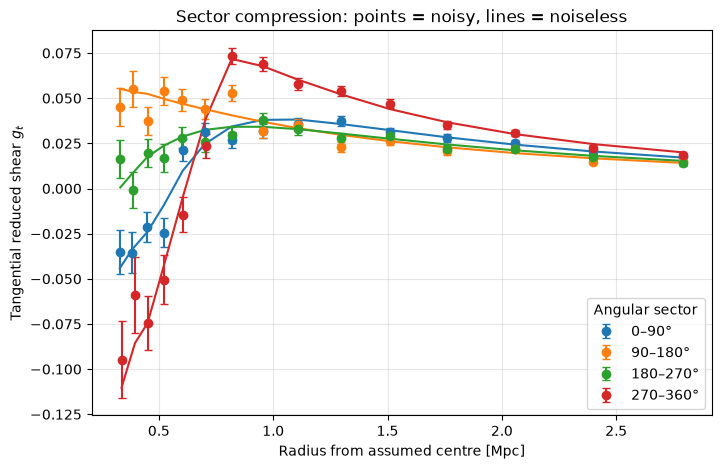

In [30]:
# Express angles in [0, 2π)
angle = np.mod(phi_assumed, 2 * np.pi)

n_bins = 15
n_sectors = 4
angle_edges = np.linspace(0, 2 * np.pi, n_sectors + 1)

R_sector = np.full((n_bins, n_sectors), np.nan)
gt_sector = np.full((n_bins, n_sectors), np.nan)
gt_true_sector = np.full((n_bins, n_sectors), np.nan)
sigma_sector = np.full((n_bins, n_sectors), np.nan)
sector_counts = np.zeros((n_bins, n_sectors), dtype=int)

for b in range(n_bins):
    #Define radial ring
    in_ring = ( 
            valid_pixels
            & (R_analysis >= bin_edges[b])
            & (R_analysis < bin_edges[b + 1])
        )
    
    # Include the outermost boundary in the last ring
    if b == n_bins - 1:
        in_ring = (
            valid_pixels
            & (R_analysis >= bin_edges[b])
            & (R_analysis <= bin_edges[b + 1])
        )

    for s in range(n_sectors):
        in_sector = (
            in_ring
            & (angle >= angle_edges[s])
            & (angle < angle_edges[s + 1])
        )
        
        print(f"Sector {s}: {in_sector.sum()} valid pixels")

        sector_counts[b, s] = in_sector.sum()
        if sector_counts[b, s] == 0:
            continue

        #Weighted mean in each ring
        weights = 1.0 / sigma[in_sector]**2
        weight_sum = weights.sum()

        R_sector[b, s] = np.sum(weights * R_analysis[in_sector]) / weight_sum
        gt_sector[b, s] = np.sum(weights * gt_obs[in_sector]) / weight_sum
        gt_true_sector[b, s] = np.sum(weights * gt_true[in_sector]) / weight_sum
        sigma_sector[b, s] = 1.0 / np.sqrt(weight_sum)

populated = pixel_counts > 0

#Plotting
fig, ax = plt.subplots(figsize=(8, 5))

for s in range(n_sectors):
    populated = sector_counts[:, s] > 0
    colour = f"C{s}"

    lower = np.degrees(angle_edges[s])
    upper = np.degrees(angle_edges[s + 1])

    ax.errorbar(
        R_sector[populated, s],
        gt_sector[populated, s],
        yerr=sigma_sector[populated, s],
        fmt="o", capsize=3, color=colour,
        label=f"{lower:.0f}–{upper:.0f}°",
    )
    ax.plot(
        R_sector[populated, s],
        gt_true_sector[populated, s],
        "-", color=colour,
    )

ax.set(
    xlabel="Radius from assumed centre [Mpc]",
    ylabel="Tangential reduced shear $g_t$",
    title="Sector compression: points = noisy, lines = noiseless",
)
ax.legend(title="Angular sector")
ax.grid(alpha=0.3)
plt.show()

In [31]:
# Compare existing sector counts with existing radial counts,
# separately for every ring.
np.testing.assert_array_equal(
    sector_counts.sum(axis=1),
    pixel_counts,
)

# Check that the rings cover all valid pixels in the radial range.
in_range = (
    valid_pixels
    & (R_analysis >= bin_edges[0])
    & (R_analysis <= bin_edges[-1])
)

assert pixel_counts.sum() == in_range.sum()

print("Passed: sector counts match each ring.")
print(f"Total valid pixels included: {in_range.sum()}")

# Reconstruct each radial average from its sector summaries.
gt_reconstructed = np.full(n_bins, np.nan)
sigma_reconstructed = np.full(n_bins, np.nan)

for b in range(n_bins):
    populated = sector_counts[b] > 0
    if not np.any(populated):
        continue

    # One weight per sector, based on uncertainty of its average
    weights = 1.0 / sigma_sector[b, populated]**2
    weight_sum = weights.sum()

    gt_reconstructed[b] = (
        np.sum(weights * gt_sector[b, populated]) / weight_sum
    )
    sigma_reconstructed[b] = 1.0 / np.sqrt(weight_sum)

# Compare reconstructed rings against the original radial results.
populated_rings = pixel_counts > 0

np.testing.assert_allclose(
    gt_reconstructed[populated_rings],
    gt_radial[populated_rings],
    rtol=1e-6,
    atol=1e-10,
)

np.testing.assert_allclose(
    sigma_reconstructed[populated_rings],
    sigma_radial[populated_rings],
    rtol=1e-6,
    atol=1e-10,
)

print("Passed: sectors reproduce radial averages and uncertainties.")

Passed: sector counts match each ring.
Total valid pixels included: 7712
Passed: sectors reproduce radial averages and uncertainties.


# Mock dataset
100 simulations

In [40]:
import numpy as np
from cosmology import Cosmology
from compression import radial_compression, sector_compression

map_half_width = 3.0  # Mpc
n_side = 100
pixel_edges = np.linspace(-map_half_width, map_half_width, n_side + 1)
pixel_centres = 0.5 * (pixel_edges[:-1] + pixel_edges[1:])
x, y = np.meshgrid(pixel_centres, pixel_centres)
pixel_size = pixel_edges[1] - pixel_edges[0]
pixel_area = pixel_size**2

true_centre = (0.4, -0.2)
assumed_centre = (0.0, 0.0)
R_true = np.hypot(x - true_centre[0], y - true_centre[1])
phi_assumed = np.arctan2(y - assumed_centre[1], x - assumed_centre[0])

#Calculating each pixel's geometry relative to the assumed centre
R_analysis = np.hypot(x - assumed_centre[0], y - assumed_centre[1])
mask = (
    (R_analysis >= 0.3)
    & (R_analysis <= 3.0)
    & (R_true >= 0.3)
)
count_map = np.where(mask, N_per_pixel, 0)

gt_map = np.zeros_like(R)
gt_map[mask] = shear_profile(
    theta=theta,
    R=R[mask],
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)
# Radial
n_bins = 15
bin_edges = np.geomspace(0.3, 3.0, n_bins + 1)
sigma = sigma_pixel.detach().cpu().numpy()
valid_pixels = (
    valid.cpu().numpy()
    & np.isfinite(sigma)
    & (sigma > 0)
)

gt_true = (
    -g1_true * np.cos(2 * phi_assumed)
    -g2_true * np.sin(2 * phi_assumed)
)

R_radial = np.full(n_bins, np.nan)
gt_radial = np.full(n_bins, np.nan)
gt_true_radial = np.full(n_bins, np.nan)
sigma_radial = np.full(n_bins, np.nan)
pixel_counts = np.zeros(n_bins, dtype=int)

#Sector
n_sectors = 4
angle_edges = np.linspace(0, 2 * np.pi, n_sectors + 1)

In [41]:
#Sample 100 mass-concentration pairs
n_simulations = 100
rng = np.random.default_rng(42)
torch.manual_seed(42)

parameters = np.column_stack([
    rng.uniform(14.0, 15.0, n_simulations),  # log10(M200c / solar mass)
    rng.uniform(2.0, 7.0, n_simulations),    # c200c
])

print(parameters.shape)  # (100, 2)

maps = []
radial_profiles = []
radial_errors = []
radial_valid = []

sector_profiles = []
sector_errors = []
sector_valid = []

(100, 2)


In [42]:
from lensing import simulate_map
from compression import (
    project_shear,
    radial_compression,
    sector_compression,
)

for log_mass, concentration in parameters:
    theta_i = [
        log_mass,
        concentration,
        true_centre[0],
        true_centre[1],
        z_lens,
        z_source,
    ]

    # One noisy observation for this halo
    g_obs_i, g_true_i, sigma_i, valid_i = simulate_map(
        theta=theta_i,
        x=x,
        y=y,
        centre=true_centre,
        mask=mask,
        z_l=z_lens,
        Sigma_crit=Sigma_crit,
        cosmology=cosmology,
        N_per_pixel=count_map,
        sigma_galaxy=sigma_galaxy,
    )

    # Analyse that observation around the assumed centre
    radius, angle, gt_i, gx_i = project_shear(
        g_obs_i, x, y, assumed_centre
    )

    radial_i = radial_compression(
        gt_i, radius, sigma_i, valid_i, bin_edges
    )

    sector_i = sector_compression(
        gt_i, radius, angle, sigma_i, valid_i,
        bin_edges, angle_edges,
    )

    maps.append(g_obs_i.detach().cpu().numpy())

    radial_profiles.append(radial_i.shear)
    radial_errors.append(radial_i.uncertainty)
    radial_valid.append(radial_i.valid)

    sector_profiles.append(sector_i.shear)
    sector_errors.append(sector_i.uncertainty)
    sector_valid.append(sector_i.valid)

In [43]:
#Converting from lists to dataset arrays
maps = np.stack(maps)
radial_profiles = np.stack(radial_profiles)
radial_errors = np.stack(radial_errors)
radial_valid = np.stack(radial_valid)

sector_profiles = np.stack(sector_profiles)
sector_errors = np.stack(sector_errors)
sector_valid = np.stack(sector_valid)

print("Parameters:", parameters.shape)
print("Maps:", maps.shape)
print("Radial:", radial_profiles.shape)
print("Sectors:", sector_profiles.shape)

Parameters: (100, 2)
Maps: (100, 2, 100, 100)
Radial: (100, 15)
Sectors: (100, 15, 4)


In [44]:
#Save data and fixed observing information
np.savez_compressed(
    "paired_mocks.npz",
    parameters=parameters,
    parameter_names=np.array(["log10_M200c", "c200c"]),
    maps=maps,
    radial_profiles=radial_profiles,
    radial_errors=radial_errors,
    radial_valid=radial_valid,
    sector_profiles=sector_profiles,
    sector_errors=sector_errors,
    sector_valid=sector_valid,
    pixel_valid=valid_i.cpu().numpy(),
    pixel_sigma=sigma_i.cpu().numpy(),
    count_map=count_map,
    x=x,
    y=y,
    bin_edges=bin_edges,
    angle_edges=angle_edges,
    true_centre=true_centre,
    assumed_centre=assumed_centre,
    sigma_galaxy=sigma_galaxy,
    z_lens=z_lens,
    z_source=z_source,
    H0=cosmology.H0,
    Omega_m=cosmology.Omega_m,
    Omega_lambda=cosmology.Omega_lambda,
)

In [45]:
# Compare counts from the same simulated observation
np.testing.assert_array_equal(
    sector_i.counts.sum(axis=1),
    radial_i.counts,
)

# Reconstruct radial averages from its sector results
for b in range(len(radial_i.shear)):
    if not radial_i.valid[b]:
        continue

    populated = sector_i.valid[b]
    weights = 1.0 / sector_i.uncertainty[b, populated]**2

    reconstructed_gt = (
        np.sum(weights * sector_i.shear[b, populated])
        / weights.sum()
    )
    reconstructed_sigma = 1.0 / np.sqrt(weights.sum())

    np.testing.assert_allclose(
        reconstructed_gt,
        radial_i.shear[b],
        rtol=1e-6,
        atol=1e-10,
    )
    np.testing.assert_allclose(
        reconstructed_sigma,
        radial_i.uncertainty[b],
        rtol=1e-6,
        atol=1e-10,
    )

print("Passed: last mock's sector and radial results agree.")

Passed: last mock's sector and radial results agree.


# Fisher matrix
## Gaussian likelihood posterior

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from cosmology import Cosmology
from lensing import shear_profile
from compression import project_shear, radial_compression

with np.load("paired_mocks.npz") as data:
    i = 0
    observed = data["radial_profiles"][i].copy()
    uncertainty = data["radial_errors"][i].copy()
    usable = data["radial_valid"][i].copy()
    theta_true = data["parameters"][i].copy()

    x = data["x"].copy()
    y = data["y"].copy()
    pixel_valid = data["pixel_valid"].copy()
    pixel_sigma = data["pixel_sigma"].copy()
    bin_edges = data["bin_edges"].copy()

    true_centre = data["true_centre"].copy()
    assumed_centre = data["assumed_centre"].copy()
    z_lens = float(data["z_lens"])
    z_source = float(data["z_source"])

    cosmology = Cosmology(
        H0=float(data["H0"]),
        Omega_m=float(data["Omega_m"]),
        Omega_lambda=float(data["Omega_lambda"]),
    )

usable &= (
np.isfinite(observed)
& np.isfinite(uncertainty)
& (uncertainty > 0)
)

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)

print("True [log10 mass, concentration]:", theta_true)
print("Number of usable radial bins:", usable.sum())

True [log10 mass, concentration]: [14.77395605  6.54290345]
Number of usable radial bins: 15


In [ ]:
# Define a grid of parameter values
from lensing import simulate_map
from compression import (
    project_shear,
    radial_compression,
    sector_compression,
)

R_true = np.hypot(
    x - true_centre[0],
    y - true_centre[1],
)

phi_true = np.arctan2(
    y - true_centre[1],
    x - true_centre[0],
)

assert np.all(R_true[pixel_valid] > 0)

def predict_radial(log_mass, concentration):
    """Noiseless radial summary for one candidate halo."""

    theta = [log_mass, concentration]

    # Tangential signal around the physical halo centre
    gt_map = np.zeros_like(x, dtype=float)

    gt_map[pixel_valid] = shear_profile(
        theta=theta,
        R=R_true[pixel_valid],
        z_l=z_lens,
        Sigma_crit=Sigma_crit,
        cosmology=cosmology,
    ).detach().cpu().numpy()

    # Convert into fixed-coordinate shear components
    g1 = -gt_map * np.cos(2 * phi_true)
    g2 = -gt_map * np.sin(2 * phi_true)
    model_map = np.stack([g1, g2])

    # Analyse around the same assumed centre used for the observation
    radius, angle, gt_analysis, gx_analysis = project_shear(
        model_map, x, y, assumed_centre
    )

    # Apply the same compression and weights
    result = radial_compression(
        gt_analysis,
        radius,
        pixel_sigma,
        pixel_valid,
        bin_edges,
    )

    return result.shear

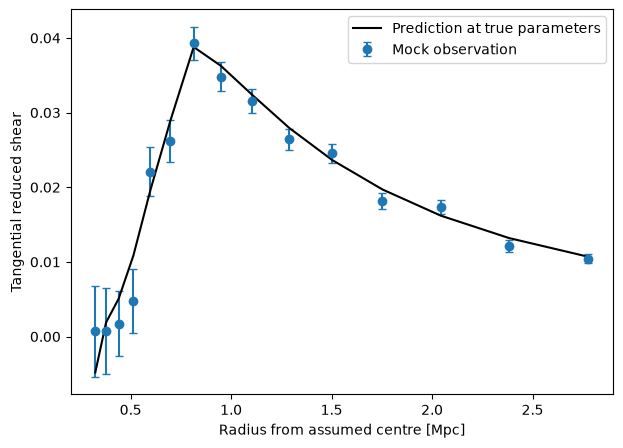

Standardized residuals: [ 0.90034712 -0.20358629 -0.768311   -1.40277358  0.74707833 -0.98168238
  0.22433249 -0.74031432 -0.48166818 -1.08737611  0.73642019 -1.47447876
  1.30621324 -1.40508557 -0.35696653]


In [54]:
prediction_true = predict_radial(*theta_true)

assert np.all(np.isfinite(prediction_true[usable]))

# Geometric bin centres are sufficient for displaying this comparison.
R_display = np.sqrt(bin_edges[:-1] * bin_edges[1:])

fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    R_display[usable],
    observed[usable],
    yerr=uncertainty[usable],
    fmt="o",
    capsize=3,
    label="Mock observation",
)
ax.plot(
    R_display[usable],
    prediction_true[usable],
    "k-",
    label="Prediction at true parameters",
)
ax.set(
    xlabel="Radius from assumed centre [Mpc]",
    ylabel="Tangential reduced shear",
)
ax.legend()
plt.show()

residual_true = (
    observed[usable] - prediction_true[usable]
) / uncertainty[usable]

print("Standardized residuals:", residual_true)

### Define a parameter grid and prior

In [55]:
log_mass_grid = np.linspace(14.0, 15.0, 50)
concentration_grid = np.linspace(2.0, 7.0, 50)

log_likelihood = np.empty(
    (len(log_mass_grid), len(concentration_grid))
)

### Evaluate likelihood at every grid point

$$ \log L(\theta) =-\frac12\sum_b\frac{[d_b-\mu_b(\theta)]^2}{\sigma_b^2}+\text{constant}. $$

where $ d_b $ is the observation and $ \mu_b(\theta) $ is the noiseless prediction

In [56]:
for i, log_mass in enumerate(log_mass_grid):
    for j, concentration in enumerate(concentration_grid):
        prediction = predict_radial(log_mass, concentration)

        residual = (
            observed[usable] - prediction[usable]
        ) / uncertainty[usable]

        log_likelihood[i, j] = -0.5 * np.sum(residual**2)

### Normalize the posterior

In [57]:
# Subtract the maximum to avoid numerical underflow.
posterior = np.exp(log_likelihood - log_likelihood.max())
posterior /= posterior.sum()

best_index = np.unravel_index(
    np.argmax(posterior), posterior.shape
)

theta_best = np.array([
    log_mass_grid[best_index[0]],
    concentration_grid[best_index[1]],
])

print("True parameters:", theta_true)
print("Highest-posterior grid point:", theta_best)

True parameters: [14.77395605  6.54290345]
Highest-posterior grid point: [14.75510204  6.79591837]


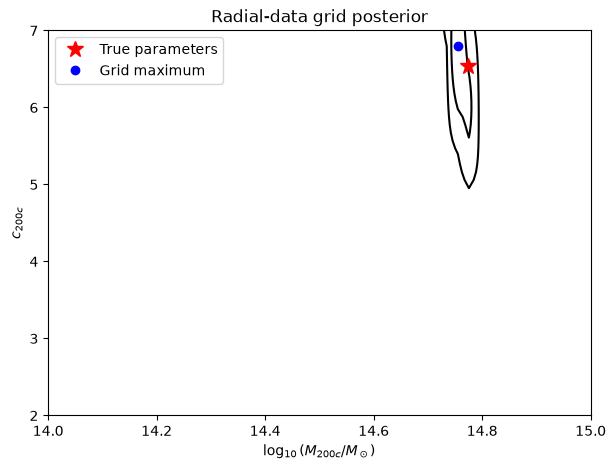

In [60]:
sorted_probability = np.sort(posterior.ravel())[::-1]
cumulative_probability = np.cumsum(sorted_probability)

thresholds = []
for probability in [0.68, 0.95]:
    index = np.searchsorted(cumulative_probability, probability)
    index = min(index, len(sorted_probability) - 1)
    thresholds.append(sorted_probability[index])

levels = np.unique(np.sort(thresholds))

mass_mesh, concentration_mesh = np.meshgrid(
    log_mass_grid,
    concentration_grid,
    indexing="ij",
)

fig, ax = plt.subplots(figsize=(7, 5))
ax.contour(
    mass_mesh,
    concentration_mesh,
    posterior,
    levels=levels,
    colors="black",
)
ax.plot(*theta_true, "r*", markersize=12, label="True parameters")
ax.plot(*theta_best, "bo", label="Grid maximum")
ax.set(
    xlabel=r"$\log_{10}(M_{200c}/M_\odot)$",
    ylabel=r"$c_{200c}$",
    title="Radial-data grid posterior",
)
ax.legend()
plt.show()

## Fisher matrix

In [ ]:
from compression import radial_compression, sector_compression

def predict_radial(log_mass, concentration):
    # Fixed physical geometry
    R_true = np.hypot(
        x - true_centre[0],
        y - true_centre[1],
    )
    phi_true = np.arctan2(
        y - true_centre[1],
        x - true_centre[0],
    )

    # Noiseless signal at valid pixel centres
    gt_map = np.zeros_like(x, dtype=float)
    gt_map[pixel_valid] = shear_profile(
        theta=[log_mass, concentration],
        R=R_true[pixel_valid],
        z_l=z_lens,
        Sigma_crit=Sigma_crit,
        cosmology=cosmology,
    ).detach().cpu().numpy()

    model_map = np.stack([
        -gt_map * np.cos(2 * phi_true),
        -gt_map * np.sin(2 * phi_true),
    ])

    # Same analysis centre and compression as the observation
    radius, angle, gt, gx = project_shear(
        model_map, x, y, assumed_centre
    )

    result = radial_compression(
        gt, radius, pixel_sigma, pixel_valid, bin_edges
    )

    return result.shear

theta_ref = theta_best.copy()
halo = NFWHalo(
    theta=theta_ref,
    z_l=0.3,              # Lens redshift
    cosmology=cosmology,
)

r_s, rho_s = halo.nfw_parameters()
# Choose 30 projected physical radii from 0.1 to 3 Mpc.
R = np.geomspace(0.1, 3.0, 30)

Sigma, Sigma_mean = halo.surface_densities(R)
DeltaSigma = Sigma_mean - Sigma

Sigma_crit = cosmology.critical_surface_density(z_lens, z_source)
g_t = shear_profile(
    theta=theta_ref,
    R=R,
    z_l=z_lens,
    Sigma_crit=Sigma_crit,
    cosmology=cosmology,
)

#Reference values
log_mass_ref = theta_ref[0]
concentration_ref = theta_ref [1]
h1 = 0.001              #small change in log mass
h2 = 0.01               #small change in concentration

def calculate_fisher (theta_ref, steps):
    # Change log mass; hold concentration fixed.
    mu_mass_plus = predict_radial(
        log_mass_ref + h1, concentration_ref
    )
    mu_mass_minus = predict_radial(
        log_mass_ref - h1, concentration_ref
    )
    dmu_dlogmass = (mu_mass_plus - mu_mass_minus) / (2 * h1)

    # Change concentration; hold log mass fixed.
    mu_concentration_plus = predict_radial(
        log_mass_ref, concentration_ref + h2
    )
    mu_concentration_minus = predict_radial(
        log_mass_ref, concentration_ref - h2
    )
    dmu_dconcentration = (
        mu_concentration_plus - mu_concentration_minus) / (2 * h2)
    # uncertainty and usable refer to the selected RADIAL observation.
    J = np.column_stack([
        dmu_dlogmass[usable],
        dmu_dconcentration[usable],
    ])

    # Divide each bin's derivatives by that bin's uncertainty.
    J_scaled = J / uncertainty[usable, None]

    return J_scaled.T @ J_scaled

steps = np.array([0.001, 0.01])
F = calculate_fisher(theta_ref, steps)
# Check sensitivity to the finite-difference step sizes.
F_half_step = calculate_fisher(theta_ref, steps / 2)

relative_change = (
    np.linalg.norm(F_half_step - F) / np.linalg.norm(F)
)
print("Relative Fisher change when halving steps:", relative_change)